# Bayesian Inference with Spectral Constraints: CTCV J2056-3014

This notebook extends the analysis from `07_bayesian_inference.ipynb` by incorporating X-ray spectral constraints ($L_X$ and $kT_{\text{max}}$) directly into the likelihood. This addresses the M–$\dot{M}$ prior correlation from spectral fitting (Salcedo+2024) by replacing informative spectral mass priors with broad population priors, and letting the spectral observables constrain the parameters through the physics.

**Data sources:**
- $\dot{P}_{\rm obs} = 0.0 \pm 1.7 \times 10^{-15}$ s/s (Salcedo+2024, Section 3.3)
- $L_X = 1.8 \times 10^{31}$ erg/s (0.3–12 keV, low state; Salcedo+2024)
- $kT_{\rm max} = 16.3^{+1.9}_{-1.8}$ keV (MKCFLOW; Salcedo+2024, Table 6)

In [18]:
import numpy as np
from scipy.interpolate import interp1d
from scipy.stats import norm
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import corner
import dynesty
from dynesty import utils as dyfunc
from dynesty import plotting as dyplot

plt.rcParams.update({
    'font.size': 13,
    'axes.labelsize': 13,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'figure.constrained_layout.use': True,
})

savedir = '../paper_figures' 

## Constants, Data, and WD Mass-Radius-Inertia Relation

In [2]:
# --- Physical constants (CGS) ---
G = 6.674e-8       # cm^3 g^-1 s^-2
Msun = 1.989e33    # g
Rsun = 6.957e10    # cm
m_H = 1.6726e-24   # proton mass [g]
keV_to_erg = 1.602e-9  # keV -> erg

# --- Measured timing data (1-sigma) ---
P = 29.609685843       # spin period [s]
Pdot_obs = 0.0         # observed Pdot [s/s]
sigma_Pdot = 1.7e-15   # 1-sigma uncertainty on Pdot [s/s]

# --- Spectral observables (Salcedo+2024) ---
# X-ray luminosity: F_X(unabs, 0.3-12 keV) = 2.2e-12 erg/s/cm^2, d = 261.6 +/- 7.4 pc
d_pc = 261.6                           # distance [pc]
sigma_d_pc = 7.4                       # 1-sigma distance error [pc]
d_cm = d_pc * 3.086e18                 # distance [cm]
F_X = 2.2e-12                          # unabsorbed flux [erg/s/cm^2]
sigma_FX_frac = 0.05                   # ~5% flux uncertainty (spectral fit)
L_X_obs = 4 * np.pi * d_cm**2 * F_X   # X-ray luminosity [erg/s], 0.3-12 keV band
# Propagate distance + flux uncertainties
sigma_LX = L_X_obs * np.sqrt((2 * sigma_d_pc / d_pc)**2 + sigma_FX_frac**2)

# X-ray band for the bolometric -> band-limited correction applied to L_X_pred
LX_BAND_LO = 0.3   # keV
LX_BAND_HI = 12.0  # keV

# kT_max from MKCFLOW (Salcedo+2024, Table 6)
# 90% CI: 16.3 +1.9/-1.8 keV -> 1-sigma ~ 1.9/1.645 ~ 1.15 keV
kT_obs = 16.3        # keV
sigma_kT = 1.15       # 1-sigma [keV]

# Mean molecular weight for fully ionized solar-composition plasma
mu_mol = 0.617
# Empirical correction factor (Yu+2018, calibrated on 11 nmCVs)
alpha_Yu = 0.646

# --- Load WD mass-radius-inertia table ---
mr_data = np.loadtxt('../wd_mass_radius/mass_radius.txt', delimiter=',', skiprows=1)
M_table = mr_data[:, 0]   # M_sun
R_table = mr_data[:, 1]   # R_sun
I_table = mr_data[:, 2]   # g cm^2

# Interpolators: input in solar masses, output in CGS
get_R = interp1d(M_table, R_table * Rsun, kind='cubic')   # returns cm
get_I = interp1d(M_table, I_table, kind='cubic')           # returns g cm^2

M_min_table = M_table.min()
M_max_table = M_table.max()

# --- Magnetosphere geometry ---
# xi: magnetospheric-radius prefactor, r_m = xi * r_Alfven (Ghosh & Lamb 1979).
#     Conventional disk-accretion value is ~0.5, literature range ~0.3-1.
#     Since r_m ~ B^(4/7), the inferred B scales as xi^(-7/4); a factor-2
#     uncertainty in xi maps to ~3.4x on B. We marginalise over xi as a
#     sampled nuisance parameter so the B posterior reflects this systematic.

print(f"Table range: {M_min_table:.3f} - {M_max_table:.3f} Msun")
print(f"L_X_obs = {L_X_obs:.2e} erg/s  (sigma = {sigma_LX:.2e})")
print(f"kT_obs  = {kT_obs:.1f} +/- {sigma_kT:.2f} keV (1-sigma)")


Table range: 0.010 - 1.406 Msun
L_X_obs = 1.80e+31 erg/s  (sigma = 1.36e+30)
kT_obs  = 16.3 +/- 1.15 keV (1-sigma)


## Forward Models

We model CJ2056 as an **accreting intermediate polar**. The observed hard thermal X-ray emission ($kT \approx 16$ keV, $L_X \approx 10^{31}$ erg/s) is an accretion-shock signature, so we restrict the IP model to $r_m \in [R_{\rm WD}, r_{\rm co}]$ (no propeller regime) throughout.

**Pdot** follows Bhattacharyya & Chakrabarty (2017, Eq. 9) in the accretion regime.

**Spectral forward models:**

*nmCV:*
- $kT_{\text{pred}} = \frac{3}{16} \alpha \mu_{\text{mol}} m_H \frac{GM}{R}$ (Yu+2018, $\alpha = 0.646$)
- $L_{X,\text{pred}} = f_{\rm band}(kT_{\rm pred}) \cdot \frac{GM\dot{M}}{R}$

*IP:*
- $kT_{\text{pred}} = \frac{3}{16} \mu_{\text{mol}} m_H \cdot 2GM\left(\frac{1}{R} - \frac{1}{r_m}\right)$ (Rankine-Hugoniot strong shock, $\gamma = 5/3$)
- $L_{X,\text{pred}} = f_{\rm band}(kT_{\rm pred}) \cdot GM\dot{M}\left(\frac{1}{R} - \frac{1}{r_m}\right)$

Samples with $r_m \le R_{\rm WD}$ or $r_m > r_{\rm co}$ are rejected by the likelihood (forward models return NaN).

**Band correction.** Theoretical accretion luminosities are bolometric, whereas $L_{X,\rm obs}$ is the unabsorbed flux in 0.3-12 keV. For single-temperature thermal bremsstrahlung with Gaunt factor $g_{\rm ff} \approx 1$,
$$f_{\rm band}(kT) = \exp(-E_{\rm lo}/kT) - \exp(-E_{\rm hi}/kT),$$
evaluated at the predicted $kT$. At $kT \sim 16$ keV this gives $f_{\rm band} \approx 0.5$.


In [3]:
# =====================================================
# Pdot forward models (Bhattacharyya & Chakrabarty 2017)
# =====================================================

def pdot_nmcv(M_wd_solar, log10_Mdot):
    """Predicted Pdot for the nmCV case (disk extends to WD surface, spin-up only)."""
    M = M_wd_solar * Msun
    Mdot = 10**log10_Mdot
    R = get_R(M_wd_solar)
    I = get_I(M_wd_solar)
    tau = Mdot * np.sqrt(G * M * R)
    return -P**2 * tau / (2 * np.pi * I)


def _rm_rco(M_wd_solar, log10_Mdot, log10_mu, xi):
    """Return (M, Mdot, mu, R, r_m, r_co) in CGS for an accreting IP."""
    M = M_wd_solar * Msun
    Mdot = 10**log10_Mdot
    mu = 10**log10_mu
    R = get_R(M_wd_solar)
    r_m = xi * (mu**4 / (2 * G * M * Mdot**2))**(1.0/7.0)
    r_co = (G * M * P**2 / (4 * np.pi**2))**(1.0/3.0)
    return M, Mdot, mu, R, r_m, r_co


def pdot_ip(M_wd_solar, log10_Mdot, log10_mu, xi):
    """Predicted Pdot for an accreting IP (r_m in [R_WD, r_co]).

    Bhattacharyya & Chakrabarty (2017, Eq. 9). Returns NaN outside the accretion
    range (r_m <= R_WD or r_m > r_co).
    """
    M, Mdot, mu, R, r_m, r_co = _rm_rco(M_wd_solar, log10_Mdot, log10_mu, xi)
    I = get_I(M_wd_solar)
    if r_m <= R or r_m > r_co:
        return np.nan

    x = r_m / r_co
    tau_acc = Mdot * np.sqrt(G * M * r_m)
    tau_mag = mu**2 / (9 * r_m**3) * (2 * x**3 - 6 * x**1.5 + 3)
    return -P**2 * (tau_acc + tau_mag) / (2 * np.pi * I)


# =====================================================
# Band-correction factor for the bolometric -> 0.3-12 keV conversion
# =====================================================

def f_band(kT_keV):
    """Fraction of bolometric thermal-bremsstrahlung luminosity in LX_BAND_LO..LX_BAND_HI.

    Single-temperature bremsstrahlung with Gaunt factor ~1:
        dL/dE ~ exp(-E/kT)  ->  L(E1,E2)/L_bol = exp(-E1/kT) - exp(-E2/kT).
    """
    return np.exp(-LX_BAND_LO / kT_keV) - np.exp(-LX_BAND_HI / kT_keV)


# =====================================================
# Spectral forward models
# =====================================================

def kT_nmcv(M_wd_solar):
    """Predicted maximum shock temperature for nmCV [keV] (Yu+2018 relation)."""
    M = M_wd_solar * Msun
    R = get_R(M_wd_solar)
    kT_erg = (3.0 / 16.0) * alpha_Yu * mu_mol * m_H * G * M / R
    return kT_erg / keV_to_erg


def LX_nmcv(M_wd_solar, log10_Mdot):
    """Predicted 0.3-12 keV X-ray luminosity for nmCV [erg/s]."""
    M = M_wd_solar * Msun
    R = get_R(M_wd_solar)
    Mdot = 10**log10_Mdot
    L_bol = G * M * Mdot / R
    return f_band(kT_nmcv(M_wd_solar)) * L_bol


def kT_ip(M_wd_solar, log10_Mdot, log10_mu, xi):
    """Predicted shock temperature for an accreting IP [keV].

    Returns NaN outside the accretion range (r_m <= R_WD or r_m > r_co).
    """
    M, Mdot, mu, R, r_m, r_co = _rm_rco(M_wd_solar, log10_Mdot, log10_mu, xi)
    if r_m <= R or r_m > r_co:
        return np.nan
    vff2 = 2 * G * M * (1.0 / R - 1.0 / r_m)
    kT_erg = (3.0 / 16.0) * mu_mol * m_H * vff2
    return kT_erg / keV_to_erg


def LX_ip(M_wd_solar, log10_Mdot, log10_mu, xi):
    """Predicted 0.3-12 keV X-ray luminosity for an accreting IP [erg/s]."""
    M, Mdot, mu, R, r_m, r_co = _rm_rco(M_wd_solar, log10_Mdot, log10_mu, xi)
    if r_m <= R or r_m > r_co:
        return np.nan
    vff2 = 2 * G * M * (1.0 / R - 1.0 / r_m)
    kT = (3.0 / 16.0) * mu_mol * m_H * vff2 / keV_to_erg
    L_bol = G * M * Mdot * (1.0 / R - 1.0 / r_m)
    return f_band(kT) * L_bol


# --- Sanity checks ---
print("=== Pdot checks ===")
print(f"nmCV(0.935, 15): Pdot = {pdot_nmcv(0.935, 15):.3e}")
print(f"IP(0.815, 15, 30.3, xi=0.5): Pdot = {pdot_ip(0.815, 15, 30.3, 0.5):.3e}")

print("\n=== f_band checks ===")
print(f"f_band(16.3 keV): {f_band(16.3):.3f}   (0.3-12 keV fraction at kT_obs)")
print(f"f_band(10 keV):   {f_band(10.0):.3f}")
print(f"f_band(30 keV):   {f_band(30.0):.3f}")

print("\n=== kT checks ===")
print(f"nmCV kT(0.9): {kT_nmcv(0.9):.1f} keV  (expect ~15-20 keV)")
print(f"IP kT(0.8, 14.5, 30.0, 0.5): {kT_ip(0.8, 14.5, 30.0, 0.5):.1f} keV")

print("\n=== L_X checks (band-corrected) ===")
print(f"nmCV L_X(0.9, 14.5): {LX_nmcv(0.9, 14.5):.2e} erg/s")
print(f"IP L_X(0.8, 14.5, 30.0, 0.5): {LX_ip(0.8, 14.5, 30.0, 0.5):.2e} erg/s")


=== Pdot checks ===
nmCV(0.935, 15): Pdot = -2.381e-16
IP(0.815, 15, 30.3, xi=0.5): Pdot = -3.262e-16

=== f_band checks ===
f_band(16.3 keV): 0.503   (0.3-12 keV fraction at kT_obs)
f_band(10 keV):   0.669
f_band(30 keV):   0.320

=== kT checks ===
nmCV kT(0.9): 15.7 keV  (expect ~15-20 keV)
IP kT(0.8, 14.5, 30.0, 0.5): 8.9 keV

=== L_X checks (band-corrected) ===
nmCV L_X(0.9, 14.5): 3.28e+31 erg/s
IP L_X(0.8, 14.5, 30.0, 0.5): 8.26e+30 erg/s


## Priors and Likelihood

**Priors (nmCV, 2D):**
- $M_{\rm WD}$: $\mathcal{N}(0.83, 0.20)$ (Pala+2022, volume-limited CV sample), clipped to WD table range
- $\log_{10}\dot{M}$: $\mathcal{U}(13, 17)$ (flat in log-space)

**Priors (IP, 4D):**
- $M_{\rm WD}$: $\mathcal{N}(0.83, 0.20)$ clipped to table range
- $\log_{10}\dot{M}$: $\mathcal{U}(13, 17)$
- $\log_{10}\mu$: $\mathcal{U}(29, 35)$ (magnetic dipole moment, G$\,$cm$^3$)
- $\xi$: log-uniform on $[0.3, 1.0]$ (magnetospheric-radius prefactor; Ghosh & Lamb 1979 range)

Sampling $\xi$ marginalises the factor-$\xi^{-7/4}$ systematic in $B$ into the posterior rather than fixing it at a conventional value.

**Likelihood.** All three observables ($\dot P$, $kT$, $L_X$) enter as independent Gaussians:
$$\ln\mathcal{L} = -\tfrac12\!\left[\left(\tfrac{\dot P_{\rm obs} - \dot P_{\rm pred}}{\sigma_{\dot P}}\right)^2 + \left(\tfrac{kT_{\rm obs} - kT_{\rm pred}}{\sigma_{kT}}\right)^2 + \left(\tfrac{L_{X,\rm obs} - L_{X,\rm pred}}{\sigma_{L_X}}\right)^2\right].$$

The IP forward models return NaN outside the accretion range ($r_m \in [R_{\rm WD}, r_{\rm co}]$); those samples are rejected ($\ln\mathcal{L} = -10^{100}$).


In [4]:
# =====================================================
# nmCV model: 2 parameters [M_wd, log10_Mdot]
# =====================================================

# Population mass prior (Pala+2022)
POP_M_MU, POP_M_SIG = 0.83, 0.20

# log10(Mdot) flat prior
LOGMDOT_LO, LOGMDOT_HI = 13.0, 17.0


def prior_transform_nmcv(u):
    """Map unit cube [0,1]^2 -> nmCV parameter space."""
    theta = np.empty(2)
    theta[0] = norm.ppf(u[0], loc=POP_M_MU, scale=POP_M_SIG)
    theta[0] = np.clip(theta[0], M_min_table + 0.001, M_max_table - 0.001)
    theta[1] = LOGMDOT_LO + u[1] * (LOGMDOT_HI - LOGMDOT_LO)
    return theta


def log_likelihood_nmcv(theta, sigma_Pdot_use=sigma_Pdot, include_Pdot=True):
    """Log-likelihood for nmCV model with kT + L_X (+ optional Pdot)."""
    M_wd, log_Mdot = theta
    if M_wd <= M_min_table or M_wd >= M_max_table:
        return -1e100

    kT_pred = kT_nmcv(M_wd)
    LX_pred = LX_nmcv(M_wd, log_Mdot)

    chi2  = ((kT_obs  - kT_pred) / sigma_kT)**2
    chi2 += ((L_X_obs - LX_pred) / sigma_LX)**2
    if include_Pdot:
        Pdot_pred = pdot_nmcv(M_wd, log_Mdot)
        chi2 += ((Pdot_obs - Pdot_pred) / sigma_Pdot_use)**2
    return -0.5 * chi2


# =====================================================
# IP model: 4 parameters [M_wd, log10_Mdot, log10_mu, xi]  (accreting only)
# =====================================================

LOGMU_LO, LOGMU_HI = 29.0, 35.0
XI_LO, XI_HI = 0.3, 1.0  # log-uniform prior range (Ghosh & Lamb 1979)


def prior_transform_ip(u):
    """Map unit cube [0,1]^4 -> IP parameter space."""
    theta = np.empty(4)
    theta[0] = norm.ppf(u[0], loc=POP_M_MU, scale=POP_M_SIG)
    theta[0] = np.clip(theta[0], M_min_table + 0.001, M_max_table - 0.001)
    theta[1] = LOGMDOT_LO + u[1] * (LOGMDOT_HI - LOGMDOT_LO)
    theta[2] = LOGMU_LO + u[2] * (LOGMU_HI - LOGMU_LO)
    theta[3] = 10**(np.log10(XI_LO) + u[3] * (np.log10(XI_HI) - np.log10(XI_LO)))
    return theta


def log_likelihood_ip(theta, sigma_Pdot_use=sigma_Pdot, include_Pdot=True):
    """Accreting-IP log-likelihood with kT + L_X (+ optional Pdot). Samples
    with r_m outside [R_WD, r_co] yield NaN from the forward models and are
    rejected."""
    M_wd, log_Mdot, log_mu, xi_s = theta
    if M_wd <= M_min_table or M_wd >= M_max_table:
        return -1e100

    kT_pred = kT_ip(M_wd, log_Mdot, log_mu, xi_s)
    LX_pred = LX_ip(M_wd, log_Mdot, log_mu, xi_s)
    if (np.isnan(kT_pred) or np.isnan(LX_pred)
            or kT_pred <= 0 or LX_pred <= 0):
        return -1e100

    chi2  = ((kT_obs  - kT_pred) / sigma_kT)**2
    chi2 += ((L_X_obs - LX_pred) / sigma_LX)**2
    if include_Pdot:
        Pdot_pred = pdot_ip(M_wd, log_Mdot, log_mu, xi_s)
        chi2 += ((Pdot_obs - Pdot_pred) / sigma_Pdot_use)**2
    return -0.5 * chi2


# --- Quick check ---
print(f"log L(IP, accretion):  {log_likelihood_ip([0.8, 14.5, 30.0, 0.5]):.3e}")
print(f"log L(IP, propeller rejected): {log_likelihood_ip([0.8, 14.0, 33.0, 0.5]):.3e}")


log L(IP, accretion):  -4.614e+01
log L(IP, propeller rejected): -1.000e+100


## Nested Sampling

In [5]:
print("Running IP nested sampling (4 params: M_WD, log Mdot, log mu, xi)...")
sampler_ip = dynesty.DynamicNestedSampler(
    log_likelihood_ip, prior_transform_ip, ndim=4,
    nlive=2000, bound='multi', sample='rwalk',
    rstate=np.random.Generator(np.random.PCG64(42))
)
sampler_ip.run_nested(print_progress=True)
results_ip = sampler_ip.results
print(f"IP done: logZ = {results_ip['logz'][-1]:.2f} +/- {results_ip['logzerr'][-1]:.2f}")


Running IP nested sampling (4 params: M_WD, log Mdot, log mu, xi)...


30855it [01:33, 331.12it/s, batch: 1 | bound: 2 | nc: 1 | ncall: 645486 | eff(%):  4.462 | loglstar: -1.907 < -0.004 < -0.520 | logz: -8.919 +/-  0.065 | stop:  0.738]                       

IP done: logZ = -8.92 +/- 0.05


In [6]:
print("Running nmCV nested sampling (2 params, with L_X + kT constraints)...")
sampler_nmcv = dynesty.DynamicNestedSampler(
    log_likelihood_nmcv, prior_transform_nmcv, ndim=2,
    nlive=2000, bound='multi', sample='rwalk',
    rstate=np.random.Generator(np.random.PCG64(43))
)
sampler_nmcv.run_nested(print_progress=True)
results_nmcv = sampler_nmcv.results
print(f"nmCV done: logZ = {results_nmcv['logz'][-1]:.2f} +/- {results_nmcv['logzerr'][-1]:.2f}")


Running nmCV nested sampling (2 params, with L_X + kT constraints)...


27495it [01:12, 380.11it/s, batch: 1 | bound: 2 | nc: 1 | ncall: 434979 | eff(%):  5.764 | loglstar: -1.837 < -0.000 < -0.486 | logz: -5.761 +/-  0.051 | stop:  0.743]                 

nmCV done: logZ = -5.77 +/- 0.04


## Results

In [7]:
# --- Extract equal-weight posterior samples ---

# IP
weights_ip = np.exp(results_ip['logwt'] - results_ip['logz'][-1])
weights_ip /= weights_ip.sum()
samples_ip_eq = dyfunc.resample_equal(results_ip['samples'], weights_ip)

# Derived: B = mu / R^3 (R depends on sampled M_WD)
R_samples_ip = get_R(samples_ip_eq[:, 0])
mu_samples_ip = 10**samples_ip_eq[:, 2]
B_samples_ip = mu_samples_ip / R_samples_ip**3
log10_B_samples_ip = np.log10(B_samples_ip)

# nmCV
weights_nmcv = np.exp(results_nmcv['logwt'] - results_nmcv['logz'][-1])
weights_nmcv /= weights_nmcv.sum()
samples_nmcv_eq = dyfunc.resample_equal(results_nmcv['samples'], weights_nmcv)


# --- Summary statistics ---
def summarize(samples, labels):
    for i, label in enumerate(labels):
        med = np.median(samples[:, i])
        lo, hi = np.percentile(samples[:, i], [16, 84])
        print(f'  {label}: {med:.4f}  (+{hi-med:.4f} / -{med-lo:.4f})')


def fmt(samples, idx):
    """One-line median (+hi / -lo) string for samples[:, idx]."""
    med = np.median(samples[:, idx])
    lo, hi = np.percentile(samples[:, idx], [16, 84])
    return f"{med:.3f} (+{hi-med:.3f}/-{med-lo:.3f})"


print('=== IP posteriors ===')
summarize(samples_ip_eq,
          ['M_WD [Msun]', 'log10(Mdot) [g/s]', 'log10(mu) [G cm^3]', 'xi'])
med_B = np.median(log10_B_samples_ip)
lo_B, hi_B = np.percentile(log10_B_samples_ip, [16, 84])
print(f'  log10(B) [G]: {med_B:.2f}  (+{hi_B-med_B:.2f} / -{med_B-lo_B:.2f})')
print(f'  B [MG]: {10**med_B/1e6:.4f}')
print(f'  B [kG]: {10**med_B/1e3:.2f}')

print('\n=== nmCV posteriors ===')
summarize(samples_nmcv_eq, ['M_WD [Msun]', 'log10(Mdot) [g/s]'])


=== IP posteriors ===
  M_WD [Msun]: 0.8713  (+0.1287 / -0.0814)
  log10(Mdot) [g/s]: 14.7229  (+0.0333 / -0.0341)
  log10(mu) [G cm^3]: 30.0695  (+0.3584 / -0.3269)
  xi: 0.5736  (+0.2712 / -0.1960)
  log10(B) [G]: 3.74  (+0.31 / -0.29)
  B [MG]: 0.0055
  B [kG]: 5.51

=== nmCV posteriors ===
  M_WD [Msun]: 0.9122  (+0.0294 / -0.0314)
  log10(Mdot) [g/s]: 14.2341  (+0.0333 / -0.0351)


### Bayes Factor

In [8]:
logZ_ip = results_ip['logz'][-1]
logZ_ip_err = results_ip['logzerr'][-1]
logZ_nmcv = results_nmcv['logz'][-1]
logZ_nmcv_err = results_nmcv['logzerr'][-1]

print('=== Model Evidence ===')
print(f'  ln(Z_IP)   = {logZ_ip:.2f} +/- {logZ_ip_err:.2f}')
print(f'  ln(Z_nmCV) = {logZ_nmcv:.2f} +/- {logZ_nmcv_err:.2f}')
print()


def jeffreys_scale(abs_lnBF):
    if abs_lnBF < 1:
        return 'Not worth more than a bare mention'
    elif abs_lnBF < 2.5:
        return 'Substantial'
    elif abs_lnBF < 5:
        return 'Strong'
    else:
        return 'Decisive'


lnBF = logZ_ip - logZ_nmcv
lnBF_err = np.sqrt(logZ_ip_err**2 + logZ_nmcv_err**2)
BF = np.exp(lnBF)
strength = jeffreys_scale(abs(lnBF))
favored = 'IP' if lnBF > 0 else 'nmCV'

header = f"{'Comparison':<16} {'ln(BF)':<16} {'BF':<12} Interpretation"
sep = '-' * 65
row = f"{'IP/nmCV':<16} {lnBF:+.2f} +/- {lnBF_err:.2f}  {BF:<12.4f} {strength} ({favored})"
print('=== Bayes Factor ===')
print(header)
print(sep)
print(row)

=== Model Evidence ===
  ln(Z_IP)   = -8.92 +/- 0.05
  ln(Z_nmCV) = -5.77 +/- 0.04

=== Bayes Factor ===
Comparison       ln(BF)           BF           Interpretation
-----------------------------------------------------------------
IP/nmCV          -3.15 +/- 0.07  0.0429       Strong (nmCV)


### Corner Plots

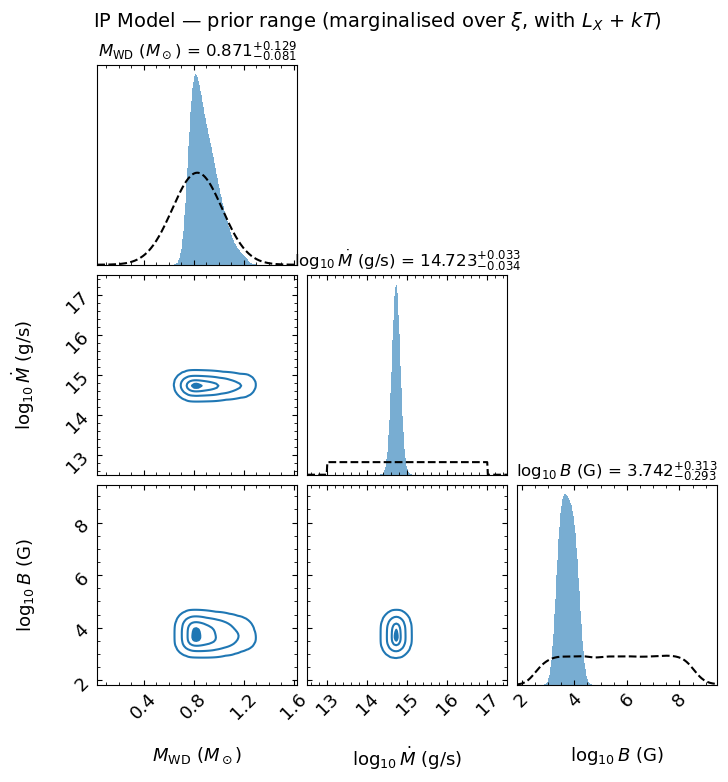

In [9]:
# --- IP corner plot (M_WD, log Mdot, log B) with prior overlays ---
# Modify column 2 in place (logmu -> logB) and use dims=[0, 1, 2] to drop xi
# from the display; xi is marginalised simply by not being plotted.
import copy
from scipy.stats import gaussian_kde


def _results_for_display(results):
    """Deepcopy a dynesty Results object and replace column 2 (log mu) with
    log10 B = log10 mu - 3 log10 R, in place."""
    rcp = copy.deepcopy(results)
    samp = rcp['samples']
    R_arr = get_R(samp[:, 0])
    samp[:, 2] = samp[:, 2] - 3 * np.log10(R_arr)
    return rcp


def overlay_prior(ax, grid, pdf, **kwargs):
    """Scale prior PDF to match histogram area (reads ax.patches from dyplot bars)."""
    hist_area = sum(p.get_width() * p.get_height()
                    for p in ax.patches if p.get_height() > 0)
    if hist_area <= 0:
        return
    prior_area = np.trapezoid(pdf, grid)
    if prior_area <= 0:
        return
    pdf_scaled = pdf * (hist_area / prior_area)
    ax.plot(grid, pdf_scaled, **kwargs)
    ymax = max(ax.get_ylim()[1], pdf_scaled.max() * 1.05)
    ax.set_ylim([0, ymax])


results_ip_B = _results_for_display(results_ip)

# Compute B prior samples for overlay (log-uniform mu marginalised over N(M))
np.random.seed(42)
N_prior = 50000
M_prior = np.random.normal(POP_M_MU, POP_M_SIG, N_prior)
M_prior = np.clip(M_prior, M_min_table + 0.001, M_max_table - 0.001)
logmu_prior = np.random.uniform(LOGMU_LO, LOGMU_HI, N_prior)
R_prior = get_R(M_prior)
logB_prior = logmu_prior - 3 * np.log10(R_prior)

labels_ip = [r'$M_{\rm WD}$ ($M_\odot$)', r'$\log_{10}\dot{M}$ (g/s)',
             r'$\log_{10} B$ (G)']

# --- Prior-range view ---
span_ip_wide = [
    (POP_M_MU - 4*POP_M_SIG, POP_M_MU + 4*POP_M_SIG),
    (LOGMDOT_LO - 0.5, LOGMDOT_HI + 0.5),
    (np.min(logB_prior), np.max(logB_prior) - 3),
]

plt.rcParams['figure.constrained_layout.use'] = False
fig, axes = dyplot.cornerplot(
    results_ip_B, dims=[0, 1, 2], span=span_ip_wide, labels=labels_ip,
    quantiles_2d=[0.1, 0.55, 0.93, 0.999],
    quantiles=None, show_titles=True,
    title_quantiles=[0.16, 0.5, 0.84], title_fmt='.3f',
    title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 13},
    color='C0',
)

# Overlay priors on diagonals
ax = axes[0, 0]
M_grid = np.linspace(*span_ip_wide[0], 300)
overlay_prior(ax, M_grid, norm.pdf(M_grid, POP_M_MU, POP_M_SIG),
              color='k', ls='--', lw=1.5, label='Prior')
ax = axes[1, 1]
Mdot_grid = np.linspace(*span_ip_wide[1], 300)
Mdot_prior_pdf = np.where((Mdot_grid >= LOGMDOT_LO) & (Mdot_grid <= LOGMDOT_HI),
                           1.0 / (LOGMDOT_HI - LOGMDOT_LO), 0.0)
overlay_prior(ax, Mdot_grid, Mdot_prior_pdf, color='k', ls='--', lw=1.5)
ax = axes[2, 2]
kde_B = gaussian_kde(logB_prior)
B_grid = np.linspace(*span_ip_wide[2], 300)
overlay_prior(ax, B_grid, kde_B(B_grid), color='k', ls='--', lw=1.5)

fig.suptitle(r'IP Model — prior range (marginalised over $\xi$, with $L_X$ + $kT$)',
             fontsize=14, y=1.02)
fig.savefig(f'{savedir}/bayesian_corner_ip_spectral.pdf', bbox_inches='tight')
plt.show()
plt.rcParams['figure.constrained_layout.use'] = True


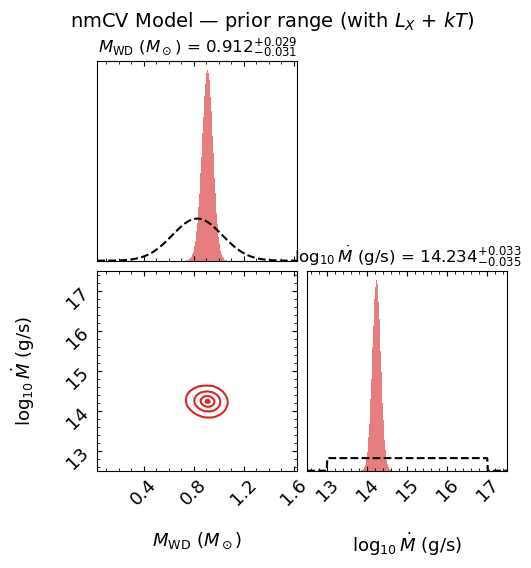

In [10]:
# --- nmCV corner plot (M_WD, log Mdot) with prior overlays ---
span_nmcv_wide = [
    (POP_M_MU - 4*POP_M_SIG, POP_M_MU + 4*POP_M_SIG),
    (LOGMDOT_LO - 0.5, LOGMDOT_HI + 0.5),
]

plt.rcParams['figure.constrained_layout.use'] = False
fig, axes = dyplot.cornerplot(
    results_nmcv, span=span_nmcv_wide,
    labels=[r'$M_{\rm WD}$ ($M_\odot$)', r'$\log_{10}\dot{M}$ (g/s)'],
    quantiles=None, show_titles=True,
    quantiles_2d=[0.1, 0.55, 0.93, 0.999],
    title_quantiles=[0.16, 0.5, 0.84], title_fmt='.3f',
    title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 13},
    color='C3',
)

ax = axes[0, 0]
M_grid = np.linspace(*span_nmcv_wide[0], 300)
overlay_prior(ax, M_grid, norm.pdf(M_grid, POP_M_MU, POP_M_SIG),
              color='k', ls='--', lw=1.5, label='Prior')
ax = axes[1, 1]
Mdot_grid = np.linspace(*span_nmcv_wide[1], 300)
Mdot_prior_pdf = np.where((Mdot_grid >= LOGMDOT_LO) & (Mdot_grid <= LOGMDOT_HI),
                           1.0 / (LOGMDOT_HI - LOGMDOT_LO), 0.0)
overlay_prior(ax, Mdot_grid, Mdot_prior_pdf, color='k', ls='--', lw=1.5)

fig.suptitle('nmCV Model — prior range (with $L_X$ + $kT$)', fontsize=14, y=1.02)
fig.savefig(f'{savedir}/bayesian_corner_nmcv_spectral.pdf', bbox_inches='tight')
plt.show()
plt.rcParams['figure.constrained_layout.use'] = True

### Predicted $\dot{P}$ Distribution

nmCV:  Pdot = -3.92e-17  (+3.14e-18 / -3.24e-18)
       range = [-5.65e-17, -2.65e-17]
       100.0% within 1-sigma of Pdot=0;  100.0% within 2-sigma

IP:  Pdot = -1.60e-16  (+1.38e-16 / -3.07e-16)
       range = [-4.48e-15, 1.28e-15]
       98.7% within 1-sigma of Pdot=0;  100.0% within 2-sigma



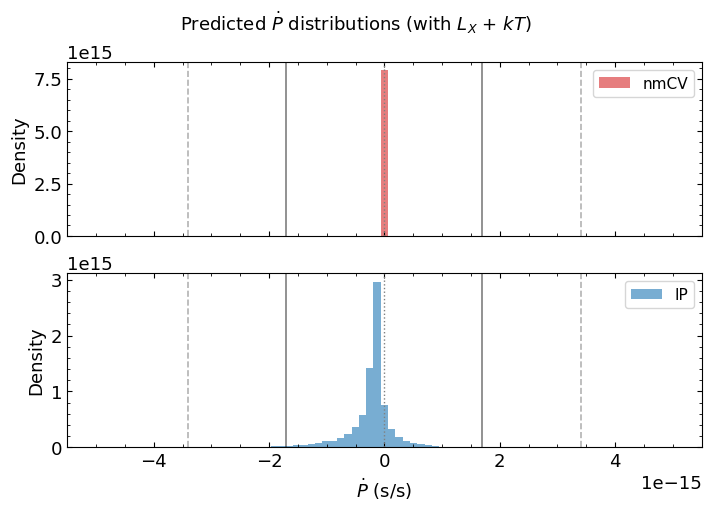

In [11]:
# Compute Pdot from posterior samples
Pdot_nmcv_samples = np.array([
    pdot_nmcv(s[0], s[1]) for s in samples_nmcv_eq
])
Pdot_ip_samples = np.array([
    pdot_ip(s[0], s[1], s[2], s[3]) for s in samples_ip_eq
])

# --- Print summary statistics ---
for name, samp in [('nmCV', Pdot_nmcv_samples), ('IP', Pdot_ip_samples)]:
    med = np.median(samp)
    lo, hi = np.percentile(samp, [16, 84])
    mn, mx = samp.min(), samp.max()
    print(f"{name}:  Pdot = {med:.2e}  (+{hi-med:.2e} / {lo-med:.2e})")
    print(f"       range = [{mn:.2e}, {mx:.2e}]")
    frac_consistent = np.mean(np.abs(samp) < sigma_Pdot) * 100
    frac_2sig = np.mean(np.abs(samp) < 2*sigma_Pdot) * 100
    print(f"       {frac_consistent:.1f}% within 1-sigma of Pdot=0;  {frac_2sig:.1f}% within 2-sigma")
    print()

fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(7, 5), sharex=True,
                                      gridspec_kw={'height_ratios': [1, 1]})

bins = np.linspace(-5e-15, 5e-15, 80)
ax_top.hist(Pdot_nmcv_samples, bins=bins, density=True, alpha=0.6, color='C3', label='nmCV')
ax_bot.hist(Pdot_ip_samples, bins=bins, density=True, alpha=0.6, color='C0', label='IP')

for ax in [ax_top, ax_bot]:
    ax.axvline(0, color='gray', ls=':', lw=1)
    for nsig, ls, alph in [(1, '-', 0.5), (2, '--', 0.3)]:
        ax.axvline(nsig * sigma_Pdot, color='k', ls=ls, alpha=alph, lw=1.2)
        ax.axvline(-nsig * sigma_Pdot, color='k', ls=ls, alpha=alph, lw=1.2)
    ax.legend(fontsize=11)
    ax.set_ylabel('Density')

ax_bot.set_xlabel(r'$\dot{P}$ (s/s)')
fig.suptitle(r'Predicted $\dot{P}$ distributions (with $L_X$ + $kT$)', fontsize=13)
fig.savefig(f'{savedir}/bayesian_pdot_posterior_spectral.pdf', bbox_inches='tight')
plt.show()


### Posterior Predictive Check

Compare the predicted observables ($kT$, $L_X$) from the posterior to the observed values.
This verifies the models actually reproduce the spectral data, and shows the per-observable
$\chi^2$ contribution.

=== Per-observable chi^2 across posterior samples ===

nmCV:  (50th, 84th, 95th, 99th percentile)
  chi2(Pdot) =   0.00    0.00    0.00    0.00
  chi2(kT)   =   0.45    1.94    3.81    6.82
  chi2(L_X)  =   0.46    2.02    3.77    6.66
  total median = 1.39

IP:  (50th, 84th, 95th, 99th percentile)
  chi2(Pdot) =   0.01    0.09    0.36    1.16
  chi2(kT)   =   0.46    1.91    3.66    6.62
  chi2(L_X)  =   0.45    1.91    3.82    6.63
  total median = 1.44



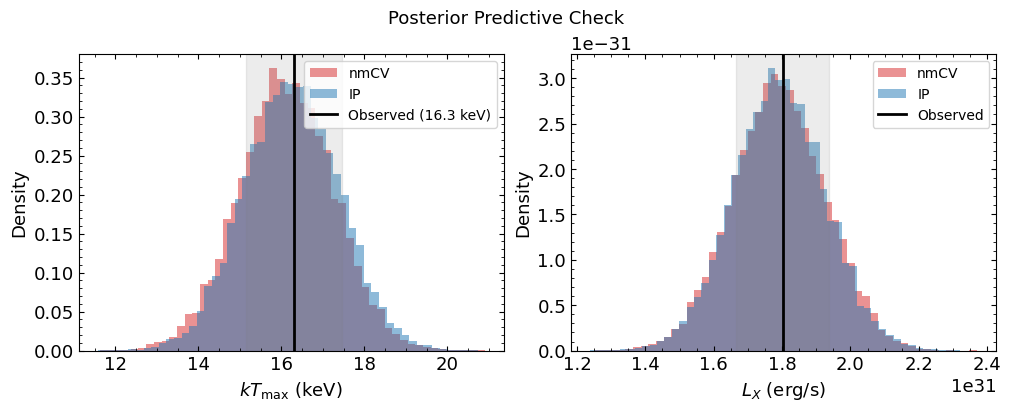

In [12]:
# --- Predicted kT and L_X from posterior ---
kT_nmcv_pred = np.array([kT_nmcv(s[0]) for s in samples_nmcv_eq])
LX_nmcv_pred = np.array([LX_nmcv(s[0], s[1]) for s in samples_nmcv_eq])

kT_ip_pred = np.array([kT_ip(s[0], s[1], s[2], s[3]) for s in samples_ip_eq])
LX_ip_pred = np.array([LX_ip(s[0], s[1], s[2], s[3]) for s in samples_ip_eq])

# --- Chi-squared breakdown (percentiles: 50th, 84th, 95th, 99th) ---
print("=== Per-observable chi^2 across posterior samples ===\n")
for name, Pdot_s, kT_s, LX_s in [
    ('nmCV', Pdot_nmcv_samples, kT_nmcv_pred, LX_nmcv_pred),
    ('IP',   Pdot_ip_samples,   kT_ip_pred,   LX_ip_pred),
]:
    chi2_Pdot = ((Pdot_obs - Pdot_s) / sigma_Pdot)**2
    chi2_kT   = ((kT_obs   - kT_s)   / sigma_kT)**2
    chi2_LX   = ((L_X_obs  - LX_s)   / sigma_LX)**2
    print(f"{name}:  (50th, 84th, 95th, 99th percentile)")
    for label, x in [('chi2(Pdot)', chi2_Pdot), ('chi2(kT)  ', chi2_kT),
                     ('chi2(L_X) ', chi2_LX)]:
        p = np.percentile(x, [50, 84, 95, 99])
        print(f"  {label} = {p[0]:6.2f}  {p[1]:6.2f}  {p[2]:6.2f}  {p[3]:6.2f}")
    print(f"  total median = {np.median(chi2_Pdot+chi2_kT+chi2_LX):.2f}\n")

# --- Plot ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# kT panel
ax = axes[0]
ax.hist(kT_nmcv_pred, bins=50, density=True, alpha=0.5, color='C3', label='nmCV')
ax.hist(kT_ip_pred,   bins=50, density=True, alpha=0.5, color='C0', label='IP')
ax.axvline(kT_obs, color='k', lw=2, label=f'Observed ({kT_obs} keV)')
ax.axvspan(kT_obs - sigma_kT, kT_obs + sigma_kT, alpha=0.15, color='gray')
ax.set_xlabel(r'$kT_{\rm max}$ (keV)')
ax.set_ylabel('Density')
ax.legend(fontsize=10)

# L_X panel
ax = axes[1]
ax.hist(LX_nmcv_pred, bins=50, density=True, alpha=0.5, color='C3', label='nmCV')
ax.hist(LX_ip_pred,   bins=50, density=True, alpha=0.5, color='C0', label='IP')
ax.axvline(L_X_obs, color='k', lw=2, label='Observed')
ax.axvspan(L_X_obs - sigma_LX, L_X_obs + sigma_LX, alpha=0.15, color='gray')
ax.set_xlabel(r'$L_X$ (erg/s)')
ax.set_ylabel('Density')
ax.legend(fontsize=10)

fig.suptitle('Posterior Predictive Check', fontsize=13)
fig.savefig(f'{savedir}/bayesian_predictive_check_spectral.pdf', bbox_inches='tight')
plt.show()


In [13]:
# --- r_m / r_co posterior (spin-equilibrium diagnostic) ---
rm_over_rco = np.zeros(len(samples_ip_eq))
for i, s in enumerate(samples_ip_eq):
    _, _, _, _, r_m_s, r_co_s = _rm_rco(s[0], s[1], s[2], s[3])
    rm_over_rco[i] = r_m_s / r_co_s

med_rr = np.median(rm_over_rco)
lo_rr, hi_rr = np.percentile(rm_over_rco, [16, 84])
print(f"r_m / r_co:  median = {med_rr:.3f}  ({lo_rr:.3f} -- {hi_rr:.3f}, 68%)")


r_m / r_co:  median = 0.701  (0.498 -- 0.894, 68%)


In [14]:
# --- Spin-evolution timescale tau = P / |Pdot| ---
tau_yr = P / np.abs(Pdot_ip_samples) / (365.25 * 86400)

med_tau = np.median(tau_yr)
lo_tau, hi_tau = np.percentile(tau_yr, [16, 84])
print(f"Spin-evolution timescale (IP):")
print(f"  tau = P/|Pdot|:  median = {med_tau:.2e} yr  ({lo_tau:.2e} -- {hi_tau:.2e}, 68%)")
print(f"  log10(tau/yr):   median = {np.log10(med_tau):.1f}")
if med_tau > 1e9:
    print(f"  >> Gyr: consistent with long-term spin equilibrium")


Spin-evolution timescale (IP):
  tau = P/|Pdot|:  median = 5.06e+09 yr  (1.82e+09 -- 1.03e+10, 68%)
  log10(tau/yr):   median = 9.7
  >> Gyr: consistent with long-term spin equilibrium


## Impact of $\dot{P}$ Measurement

Compare results with the **new** timing constraint ($\sigma_{\dot{P}} = 1.7 \times 10^{-15}$ s/s)
versus the **old** constraint ($\sigma_{\dot{P}} = 1.8 \times 10^{-12}$ s/s, essentially no Pdot information).
This isolates how much the improved timing measurement adds beyond the spectral constraints alone.

In [15]:
# --- Old-sigma_Pdot sensitivity: rerun with weak Pdot constraint, compare ln BF ---
# Same priors + accreting-IP likelihood; only sigma_Pdot changes.
sigma_Pdot_old = 1.8e-12  # essentially no Pdot constraint

print("Running IP sampling with OLD Pdot constraint (4D)...")
sampler_ip_old = dynesty.DynamicNestedSampler(
    lambda theta: log_likelihood_ip(theta, sigma_Pdot_use=sigma_Pdot_old),
    prior_transform_ip, ndim=4,
    nlive=2000, bound='multi', sample='rwalk',
    rstate=np.random.Generator(np.random.PCG64(44))
)
sampler_ip_old.run_nested(print_progress=True)
results_ip_old = sampler_ip_old.results
print(f"IP (old): logZ = {results_ip_old['logz'][-1]:.2f} +/- {results_ip_old['logzerr'][-1]:.2f}")

print("\nRunning nmCV sampling with OLD Pdot constraint...")
sampler_nmcv_old = dynesty.DynamicNestedSampler(
    lambda theta: log_likelihood_nmcv(theta, sigma_Pdot_use=sigma_Pdot_old),
    prior_transform_nmcv, ndim=2,
    nlive=2000, bound='multi', sample='rwalk',
    rstate=np.random.Generator(np.random.PCG64(45))
)
sampler_nmcv_old.run_nested(print_progress=True)
results_nmcv_old = sampler_nmcv_old.results
print(f"nmCV (old): logZ = {results_nmcv_old['logz'][-1]:.2f} +/- {results_nmcv_old['logzerr'][-1]:.2f}")

# --- Bayes factor comparison ---
lnBF_new = results_ip['logz'][-1]     - results_nmcv['logz'][-1]
lnBF_old = results_ip_old['logz'][-1] - results_nmcv_old['logz'][-1]

print("\n=== Bayes factor: IP vs nmCV, new vs old Pdot constraint ===")
print(f"  ln BF (new sigma_Pdot = {sigma_Pdot:.1e}):  {lnBF_new:+.2f}  (BF = {np.exp(lnBF_new):.4f})")
print(f"  ln BF (old sigma_Pdot = {sigma_Pdot_old:.1e}): {lnBF_old:+.2f}  (BF = {np.exp(lnBF_old):.4f})")


Running IP sampling with OLD Pdot constraint (4D)...


30903it [01:39, 309.56it/s, batch: 1 | bound: 4 | nc: 1 | ncall: 647452 | eff(%):  4.456 | loglstar: -1.878 < -0.000 < -0.506 | logz: -8.874 +/-  0.065 | stop:  0.735]                       


IP (old): logZ = -8.87 +/- 0.05

Running nmCV sampling with OLD Pdot constraint...


27569it [01:16, 361.27it/s, batch: 1 | bound: 2 | nc: 1 | ncall: 434684 | eff(%):  5.783 | loglstar: -1.907 < -0.000 < -0.533 | logz: -5.880 +/-  0.051 | stop:  0.736]                    

nmCV (old): logZ = -5.88 +/- 0.04

=== Bayes factor: IP vs nmCV, new vs old Pdot constraint ===
  ln BF (new sigma_Pdot = 1.7e-15):  -3.15  (BF = 0.0429)
  ln BF (old sigma_Pdot = 1.8e-12): -2.99  (BF = 0.0504)


## $\dot{P}$ Leverage Check (spectral-only re-run)

The posterior comparison above (new vs old $\sigma_{\dot P}$) showed essentially identical posteriors.  To verify that this is because $\dot{P}$ adds little information on top of the spectral data — not because of a model bug — we re-run the inference with $\dot{P}$ **removed entirely** from the likelihood (kT + $L_X$ only).  If the spectral-only posterior matches the with-$\dot{P}$ posterior, then $\dot{P}$ is a consistency check rather than a constraint.


In [16]:
# --- Spectral-only comparison (drop Pdot) ---
print("Running IP nested sampling (spectral-only, no Pdot)...")
sampler_ip_so = dynesty.DynamicNestedSampler(
    lambda theta: log_likelihood_ip(theta, include_Pdot=False),
    prior_transform_ip, ndim=4,
    nlive=2000, bound='multi', sample='rwalk',
    rstate=np.random.Generator(np.random.PCG64(46))
)
sampler_ip_so.run_nested(print_progress=True)
results_ip_so = sampler_ip_so.results
print(f"IP (spec-only): logZ = {results_ip_so['logz'][-1]:.2f} +/- {results_ip_so['logzerr'][-1]:.2f}")

print("\nRunning nmCV nested sampling (spectral-only, no Pdot)...")
sampler_nmcv_so = dynesty.DynamicNestedSampler(
    lambda theta: log_likelihood_nmcv(theta, include_Pdot=False),
    prior_transform_nmcv, ndim=2,
    nlive=2000, bound='multi', sample='rwalk',
    rstate=np.random.Generator(np.random.PCG64(47))
)
sampler_nmcv_so.run_nested(print_progress=True)
results_nmcv_so = sampler_nmcv_so.results
print(f"nmCV (spec-only): logZ = {results_nmcv_so['logz'][-1]:.2f} +/- {results_nmcv_so['logzerr'][-1]:.2f}")

# Equal-weight samples
w_ip_so = np.exp(results_ip_so['logwt'] - results_ip_so['logz'][-1])
w_ip_so /= w_ip_so.sum()
samples_ip_so_eq = dyfunc.resample_equal(results_ip_so['samples'], w_ip_so)

w_nmcv_so = np.exp(results_nmcv_so['logwt'] - results_nmcv_so['logz'][-1])
w_nmcv_so /= w_nmcv_so.sum()
samples_nmcv_so_eq = dyfunc.resample_equal(results_nmcv_so['samples'], w_nmcv_so)

# log B for IP spec-only
R_so = get_R(samples_ip_so_eq[:, 0])
log10_B_so = samples_ip_so_eq[:, 2] - 3 * np.log10(R_so)

# Side-by-side parameter comparison: with-Pdot vs spectral-only
print("\n=== Parameter posteriors: with Pdot vs spectral-only ===")
hdr = f"{'Parameter':<22s} {'with Pdot':<28s} {'spectral-only':<28s}"
print(hdr); print("-" * len(hdr))
print(f"{'IP M_WD [Msun]':<22s} {fmt(samples_ip_eq, 0):<28s} {fmt(samples_ip_so_eq, 0):<28s}")
print(f"{'IP log10(Mdot)':<22s} {fmt(samples_ip_eq, 1):<28s} {fmt(samples_ip_so_eq, 1):<28s}")
print(f"{'IP log10(mu)':<22s} {fmt(samples_ip_eq, 2):<28s} {fmt(samples_ip_so_eq, 2):<28s}")
print(f"{'IP xi':<22s} {fmt(samples_ip_eq, 3):<28s} {fmt(samples_ip_so_eq, 3):<28s}")
mB1 = np.median(log10_B_samples_ip); l1, h1 = np.percentile(log10_B_samples_ip, [16, 84])
mB2 = np.median(log10_B_so);         l2, h2 = np.percentile(log10_B_so, [16, 84])
print(f"{'IP log10(B)':<22s} {mB1:.2f} (+{h1-mB1:.2f}/-{mB1-l1:.2f})            "
      f"{mB2:.2f} (+{h2-mB2:.2f}/-{mB2-l2:.2f})")
print(f"{'nmCV M_WD [Msun]':<22s} {fmt(samples_nmcv_eq, 0):<28s} {fmt(samples_nmcv_so_eq, 0):<28s}")
print(f"{'nmCV log10(Mdot)':<22s} {fmt(samples_nmcv_eq, 1):<28s} {fmt(samples_nmcv_so_eq, 1):<28s}")

# Bayes factor IP vs nmCV in each setting
lnZ_ip_full   = results_ip['logz'][-1]
lnZ_nmcv_full = results_nmcv['logz'][-1]
lnZ_ip_so    = results_ip_so['logz'][-1]
lnZ_nmcv_so  = results_nmcv_so['logz'][-1]
print("\n=== Bayes factor IP vs nmCV ===")
print(f"  with Pdot:     ln BF = {lnZ_ip_full - lnZ_nmcv_full:+.2f}")
print(f"  spectral-only: ln BF = {lnZ_ip_so   - lnZ_nmcv_so:+.2f}")


Running IP nested sampling (spectral-only, no Pdot)...


30381it [01:16, 394.87it/s, batch: 1 | bound: 3 | nc: 1 | ncall: 634992 | eff(%):  4.461 | loglstar: -1.879 < -0.000 < -0.487 | logz: -8.649 +/-  0.064 | stop:  0.742]                       


IP (spec-only): logZ = -8.65 +/- 0.05

Running nmCV nested sampling (spectral-only, no Pdot)...


27519it [00:58, 467.23it/s, batch: 1 | bound: 2 | nc: 1 | ncall: 434974 | eff(%):  5.769 | loglstar: -1.831 < -0.000 < -0.455 | logz: -5.739 +/-  0.051 | stop:  0.740]                    


nmCV (spec-only): logZ = -5.75 +/- 0.04

=== Parameter posteriors: with Pdot vs spectral-only ===
Parameter              with Pdot                    spectral-only               
--------------------------------------------------------------------------------
IP M_WD [Msun]         0.871 (+0.129/-0.081)        0.871 (+0.132/-0.083)       
IP log10(Mdot)         14.723 (+0.033/-0.034)       14.724 (+0.034/-0.035)      
IP log10(mu)           30.070 (+0.358/-0.327)       30.106 (+0.339/-0.329)      
IP xi                  0.574 (+0.271/-0.196)        0.539 (+0.278/-0.177)       
IP log10(B)            3.74 (+0.31/-0.29)            3.79 (+0.30/-0.32)
nmCV M_WD [Msun]       0.912 (+0.029/-0.031)        0.913 (+0.030/-0.031)       
nmCV log10(Mdot)       14.234 (+0.033/-0.035)       14.234 (+0.034/-0.036)      

=== Bayes factor IP vs nmCV ===
  with Pdot:     ln BF = -3.15
  spectral-only: ln BF = -2.90


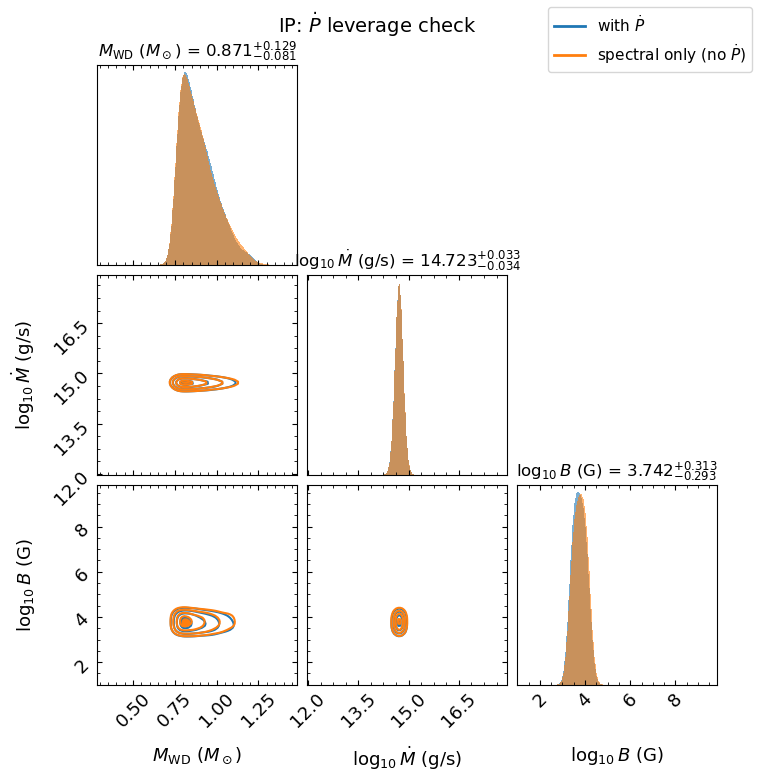

In [19]:
from matplotlib.lines import Line2D
# --- Overlay IP corner: with Pdot (blue) vs spectral-only (orange) ---
results_ip_B_full = _results_for_display(results_ip)
results_ip_B_so   = _results_for_display(results_ip_so)

all_ip_so = np.vstack([results_ip_B_full['samples'], results_ip_B_so['samples']])
span_so = []
for j in range(3):
    lo, hi = np.percentile(all_ip_so[:, j], [0.5, 99.5])
    w = hi - lo
    span_so.append((lo - 0.3 * w, hi + 0.3 * w))

labels_so = [r'$M_{\rm WD}$ ($M_\odot$)', r'$\log_{10}\dot{M}$ (g/s)',
             r'$\log_{10} B$ (G)']

plt.rcParams['figure.constrained_layout.use'] = False
fig, axes = dyplot.cornerplot(
    results_ip_B_full, dims=[0, 1, 2], span=span_so, labels=labels_so,
    quantiles=None, show_titles=True, title_quantiles=[0.16, 0.5, 0.84],
    title_fmt='.3f', title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 13},
    color='C0',
)
dyplot.cornerplot(
    results_ip_B_so, dims=[0, 1, 2], span=span_so, labels=labels_so,
    quantiles=None, show_titles=False,
    title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 13},
    color='C1', fig=(fig, axes),
)
fig.legend(handles=[
    Line2D([0], [0], color='C0', lw=2, label=r'with $\dot P$'),
    Line2D([0], [0], color='C1', lw=2, label=r'spectral only (no $\dot P$)'),
], loc='upper right', fontsize=11, frameon=True)
fig.suptitle(r'IP: $\dot P$ leverage check', fontsize=14, y=1.02)
fig.savefig(f'{savedir}/bayesian_corner_ip_pdot_leverage.pdf', bbox_inches='tight')
plt.show()
plt.rcParams['figure.constrained_layout.use'] = True


### Posterior-predictive $\dot{P}$ from the spectral-only fit

The corner overlay above shows the *symptom* (with-$\dot{P}$ vs spectral-only posteriors are nearly identical). Pushing the spectral-only posterior samples through the $\dot{P}$ forward model shows the *cause*: if the predicted $|\dot{P}|$ already sits inside $\pm\sigma_{\dot P}$, then adding the $\dot P = 0$ likelihood term has no region of parameter space left to down-weight.

=== Predicted Pdot from spectral-only posteriors ===
(measurement: Pdot_obs = 0, sigma_Pdot = 1.7e-15 s/s)

IP  : median = -1.62e-16   68% CI = [-5.41e-16, -3.81e-18]
      |Pdot| < 1 sigma_Pdot: 96.7%
      |Pdot| < 2 sigma_Pdot: 99.6%

nmCV: median = -3.92e-17   68% CI = [-4.24e-17, -3.61e-17]
      |Pdot| < 1 sigma_Pdot: 100.0%
      |Pdot| < 2 sigma_Pdot: 100.0%



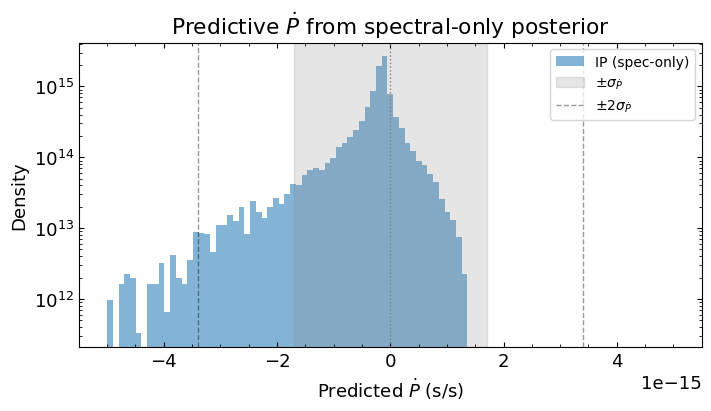

In [30]:
# =====================================================
# Posterior-predictive check: predicted Pdot from the
# spectral-only posteriors.
# Mechanistic test of the leverage finding: if spectral
# data alone already predict |Pdot| << sigma_Pdot, then
# adding the Pdot=0 likelihood term cannot down-weight
# any spectrally-allowed region.
# =====================================================

Pdot_ip_so   = np.array([pdot_ip(s[0], s[1], s[2], s[3]) for s in samples_ip_so_eq])
Pdot_nmcv_so = np.array([pdot_nmcv(s[0], s[1])           for s in samples_nmcv_so_eq])

def frac(samp, k):
    return 100 * np.mean(np.abs(samp) < k * sigma_Pdot)

print('=== Predicted Pdot from spectral-only posteriors ===')
print(f'(measurement: Pdot_obs = 0, sigma_Pdot = {sigma_Pdot:.1e} s/s)\n')
for name, samp in [('IP  ', Pdot_ip_so), ('nmCV', Pdot_nmcv_so)]:
    med = np.median(samp)
    lo, hi = np.percentile(samp, [16, 84])
    print(f'{name}: median = {med:+.2e}   68% CI = [{lo:+.2e}, {hi:+.2e}]')
    print(f'      |Pdot| < 1 sigma_Pdot: {frac(samp, 1):.1f}%')
    print(f'      |Pdot| < 2 sigma_Pdot: {frac(samp, 2):.1f}%')
    print()

fig, ax = plt.subplots(figsize=(7, 4))
ax.set_yscale('log')
bins = np.linspace(-5e-15, 5e-15, 100)
#ax.hist(Pdot_nmcv_so, bins=bins, density=False, alpha=0.55, color='C3', label='nmCV (spec-only)')
ax.hist(Pdot_ip_so,   bins=bins, density=True, alpha=0.55, color='C0', label='IP (spec-only)')
ax.axvspan(-sigma_Pdot, sigma_Pdot, color='gray', alpha=0.2, label=r'$\pm\sigma_{\dot P}$')
ax.axvline( 2*sigma_Pdot, color='k', ls='--', alpha=0.4, lw=1.0)
ax.axvline(-2*sigma_Pdot, color='k', ls='--', alpha=0.4, lw=1.0, label=r'$\pm 2\sigma_{\dot P}$')
ax.axvline(0, color='gray', ls=':', lw=1)
ax.set_xlabel(r'Predicted $\dot{P}$ (s/s)')
ax.set_ylabel('Density')
ax.set_title(r'Predictive $\dot{P}$ from spectral-only posterior')
ax.legend(fontsize=10, loc='upper right')
fig.savefig(f'{savedir}/bayesian_predictive_pdot_specOnly.pdf', bbox_inches='tight')
plt.show()
